In [ ]:
!pip -q install transformers datasets accelerate scikit-learn matplotlib seaborn pandas tqdm

In [ ]:
# %%
import re, random, string, collections
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt, seaborn as sns
from tqdm.auto import tqdm
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             roc_auc_score, confusion_matrix, roc_curve)

In [ ]:
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

In [ ]:
MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
N_DETECT = 400      # samples for detection experiment (balanced)
N_GEN = 150         # questions for generation / self-consistency experiment
N_SAMPLES = 5       # stochastic samples per question
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cuda


In [ ]:
# %% [markdown]
# ## 1. Load the dataset & EDA

# %%
ds = load_dataset("pminervini/HaluEval", "qa_samples")
split = "data" if "data" in ds else list(ds.keys())[0]
df = ds[split].to_pandas()
df["label"] = (df["hallucination"].str.lower() == "yes").astype(int)   # 1 = hallucinated
print(df.shape); df.head()

README.md:   0%|          | 0.00/2.88k [00:00<?, ?B/s]

qa_samples/data-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.43MB            

qa_samples/data-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating data split:   0%|          | 0/10000 [00:00<?, ? examples/s]

(10000, 5)


,knowledge,question,answer,hallucination,label
0,Arthur's Magazine (1844–1846) was an American ...,Which magazine was started first Arthur's Maga...,First for Women was started first.,yes,1
1,The Oberoi family is an Indian family that is ...,The Oberoi family is part of a hotel company t...,Delhi,no,0
2,"Allison Beth ""Allie"" Goertz (born March 2, 199...",Musician and satirist Allie Goertz wrote a son...,President Richard Nixon,no,0
3,"Margaret ""Peggy"" Seeger (born June 17, 1935) i...",What nationality was James Henry Miller's wife?,American,no,0
4,It is a hygroscopic solid that is highly solu...,Cadmium Chloride is slightly soluble in this c...,water with a hint of alcohol,yes,1


In [ ]:
# %%
print(df["label"].value_counts())
for c in ["knowledge", "question", "answer"]:
    df[c + "_len"] = df[c].str.split().str.len()

label
1    5010
0    4990
Name: count, dtype: int64


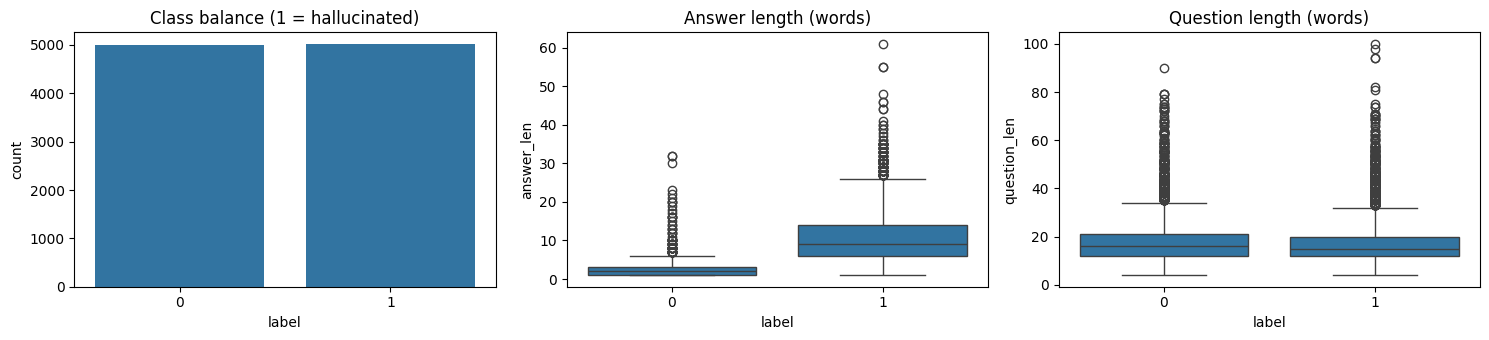

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
sns.countplot(x="label", data=df, ax=ax[0]); ax[0].set_title("Class balance (1 = hallucinated)")
sns.boxplot(x="label", y="answer_len", data=df, ax=ax[1]); ax[1].set_title("Answer length (words)")
sns.boxplot(x="label", y="question_len", data=df, ax=ax[2]); ax[2].set_title("Question length (words)")
plt.tight_layout(); plt.show()

In [ ]:
# %% [markdown]
# ## 2. Load the LLM

# %%
tok = AutoTokenizer.from_pretrained(MODEL_NAME)
tok.padding_side = "left"
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME, torch_dtype=torch.float16 if DEVICE == "cuda" else torch.float32).to(DEVICE).eval()

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

In [ ]:
def chat(prompt, system="You are a careful, factual assistant."):
    msgs = [{"role": "system", "content": system}, {"role": "user", "content": prompt}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

In [ ]:
# %% [markdown]
# ## 3. Hallucination *detection* (LLM-as-judge)
# We read the probability of the next token being "Yes" vs "No" - this gives a continuous score (for AUROC) rather than only a hard label.

# %%
YES_ID = tok.encode("Yes", add_special_tokens=False)[0]
NO_ID = tok.encode("No", add_special_tokens=False)[0]

@torch.no_grad()
def p_yes(prompts, bs=16):
    out = []
    for i in tqdm(range(0, len(prompts), bs), leave=False):
        enc = tok(prompts[i:i + bs], return_tensors="pt", padding=True, truncation=True,
                  max_length=1024).to(DEVICE)
        logits = model(**enc).logits[:, -1, :]
        pair = logits[:, [YES_ID, NO_ID]].float()
        out.extend(torch.softmax(pair, -1)[:, 0].cpu().tolist())
    return np.array(out)

In [ ]:
def judge_prompt(row, use_knowledge):
    ctx = f"Background knowledge: {row.knowledge}\n" if use_knowledge else ""
    return chat(
        f"{ctx}Question: {row.question}\nProposed answer: {row.answer}\n\n"
        "Is the proposed answer a hallucination (factually wrong or unsupported)? "
        "Reply with only Yes or No.")

# balanced evaluation subset
half = N_DETECT // 2
sub = pd.concat([df[df.label == 1].sample(half, random_state=SEED),
                 df[df.label == 0].sample(half, random_state=SEED)]).sample(frac=1, random_state=SEED).reset_index(drop=True)

sub["score_no_ctx"] = p_yes([judge_prompt(r, False) for r in sub.itertuples()])
sub["score_ctx"] = p_yes([judge_prompt(r, True) for r in sub.itertuples()])

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

In [ ]:
# %%
def evaluate(y, s, name):
    # threshold chosen as the median score so the comparison isn't dominated by model bias
    thr = np.median(s)
    pred = (s > thr).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(y, pred, average="binary", zero_division=0)
    return {"setting": name, "AUROC": roc_auc_score(y, s), "Accuracy": accuracy_score(y, pred),
            "Precision": p, "Recall": r, "F1": f1, "threshold": thr}, pred

res1, pred1 = evaluate(sub.label, sub.score_no_ctx, "Judge, no knowledge")
res2, pred2 = evaluate(sub.label, sub.score_ctx, "Judge, with knowledge")
results = pd.DataFrame([res1, res2]).round(3)
results

,setting,AUROC,Accuracy,Precision,Recall,F1,threshold
0,"Judge, no knowledge",0.701,0.670,0.670,0.670,0.670,0.589
1,"Judge, with knowledge",0.288,0.338,0.337,0.335,0.336,0.856


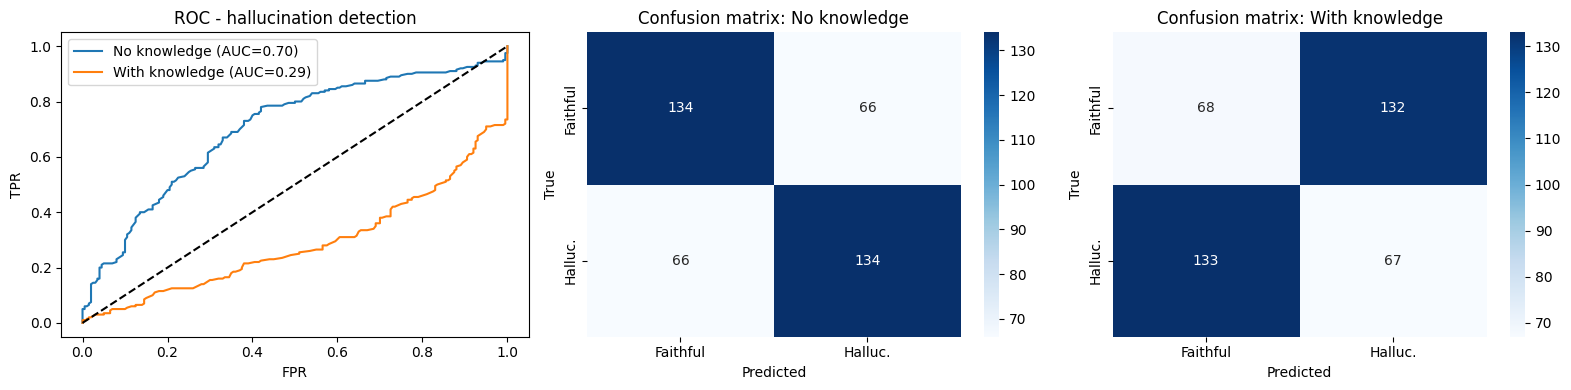

In [ ]:
# %%
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for s, name in [(sub.score_no_ctx, "No knowledge"), (sub.score_ctx, "With knowledge")]:
    fpr, tpr, _ = roc_curve(sub.label, s)
    ax[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(sub.label, s):.2f})")
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set_title("ROC - hallucination detection")
ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].legend()
for a, pred, t in [(ax[1], pred1, "No knowledge"), (ax[2], pred2, "With knowledge")]:
    sns.heatmap(confusion_matrix(sub.label, pred), annot=True, fmt="d", cmap="Blues", ax=a,
                xticklabels=["Faithful", "Halluc."], yticklabels=["Faithful", "Halluc."])
    a.set_title(f"Confusion matrix: {t}"); a.set_xlabel("Predicted"); a.set_ylabel("True")
plt.tight_layout(); plt.show()

In [ ]:
# %% [markdown]
# ## 4. Hallucination *generation* (closed-book QA)
# We ask the model the questions **without** any knowledge and compare its answers with the faithful reference answers from the dataset.
# An answer is flagged as hallucinated if it covers < 50% of the reference tokens (token recall).

# %%
def norm(t):
    t = t.lower()
    t = "".join(ch for ch in t if ch not in set(string.punctuation))
    t = re.sub(r"\b(a|an|the)\b", " ", t)
    return t.split()

def recall(ref, hyp):
    r, h = collections.Counter(norm(ref)), collections.Counter(norm(hyp))
    if not r: return 0.0
    return sum((r & h).values()) / sum(r.values())

def f1(a, b):
    ca, cb = collections.Counter(norm(a)), collections.Counter(norm(b))
    common = sum((ca & cb).values())
    if common == 0: return 0.0
    p, r = common / sum(cb.values()), common / sum(ca.values())
    return 2 * p * r / (p + r)

In [ ]:
# unique questions with a faithful reference answer
ref = df[df.label == 0].drop_duplicates("question").sample(N_GEN, random_state=SEED).reset_index(drop=True)

def qa_prompt(q):
    return chat(f"Answer the question with a short phrase (no explanation).\nQuestion: {q}")

@torch.no_grad()
def generate(prompts, bs=8, **kw):
    outs = []
    for i in tqdm(range(0, len(prompts), bs), leave=False):
        enc = tok(prompts[i:i + bs], return_tensors="pt", padding=True).to(DEVICE)
        g = model.generate(**enc, max_new_tokens=32, pad_token_id=tok.pad_token_id, **kw)
        outs.extend(tok.batch_decode(g[:, enc.input_ids.shape[1]:], skip_special_tokens=True))
    return [o.strip() for o in outs]

In [ ]:
prompts = [qa_prompt(q) for q in ref.question]
ref["greedy"] = generate(prompts, do_sample=False)
ref["recall"] = [recall(a, b) for a, b in zip(ref.answer, ref.greedy)]
ref["halluc"] = (ref.recall < 0.5).astype(int)
print(f"Closed-book hallucination rate: {ref.halluc.mean():.1%}")
ref[["question", "answer", "greedy", "recall", "halluc"]].head(10)

  0%|          | 0/19 [00:00<?, ?it/s]

Closed-book hallucination rate: 72.7%


,question,answer,greedy,recall,halluc
0,Bret Schundler served in the cabinet of a New ...,2018,2014,0.0,1
1,The Government Accountability Institute (GAI) ...,2015,2017,0.0,1
2,How many people died in the downing of the fli...,283 passengers and 15 crew,432 people died.,0.0,1
3,Life of Kylie is an American reality televisio...,nine,10 years old,0.0,1
4,What do Jimmie Ross and Jas Mann have in common?,singer,Both are country music singers.,0.0,1
5,Are 919 Third Avenue and the Morgan Stanley Bu...,yes,"Yes, both are in Manhattan.",1.0,0
6,What group did the composer of Pictures at an ...,The Five,The composer belonged to The Moscow Conservatory.,0.0,1
7,Taizô Kawashima was nominated for an Academy ...,1970,1956,0.0,1
8,Watchers is a film starring which actress?,Lala Sloatman,Emma Stone,0.0,1
9,"What is the name of this American musician, si...",Little Richard,Bob Dylan,0.0,1


In [ ]:
# %% [markdown]
# ## 5. Self-consistency as a hallucination signal
# Sample several answers at temperature 1.0. If the model *knows* the fact, samples agree with the greedy answer; if it is guessing, they scatter (idea from SelfCheckGPT).

# %%
samples = []
for rep in range(N_SAMPLES):
    samples.append(generate(prompts, do_sample=True, temperature=1.0, top_p=0.95))
samples = list(zip(*samples))   # per-question tuple of N_SAMPLES answers

ref["consistency"] = [np.mean([f1(g, s) for s in ss]) for g, ss in zip(ref.greedy, samples)]
ref["inconsistency"] = 1 - ref.consistency

  0%|          | 0/19 [00:00<?, ?it/s]

  0%|          | 0/19 [00:00<?, ?it/s]

  0%|          | 0/19 [00:00<?, ?it/s]

  0%|          | 0/19 [00:00<?, ?it/s]

  0%|          | 0/19 [00:00<?, ?it/s]

AUROC of inconsistency -> hallucination: 0.780


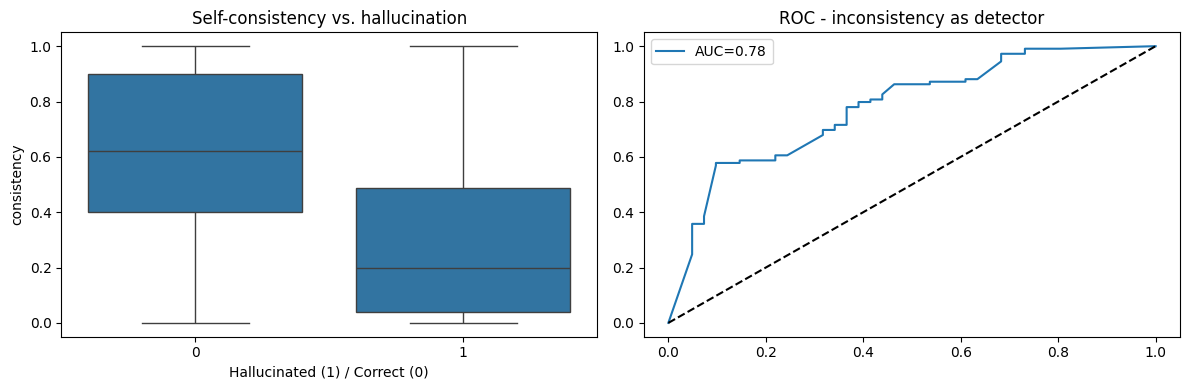

In [ ]:
auc = roc_auc_score(ref.halluc, ref.inconsistency) if ref.halluc.nunique() == 2 else float("nan")
print(f"AUROC of inconsistency -> hallucination: {auc:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x="halluc", y="consistency", data=ref, ax=ax[0])
ax[0].set_title("Self-consistency vs. hallucination"); ax[0].set_xlabel("Hallucinated (1) / Correct (0)")
fpr, tpr, _ = roc_curve(ref.halluc, ref.inconsistency)
ax[1].plot(fpr, tpr, label=f"AUC={auc:.2f}"); ax[1].plot([0, 1], [0, 1], "k--")
ax[1].set_title("ROC - inconsistency as detector"); ax[1].legend()
plt.tight_layout(); plt.show()

In [ ]:
# %% [markdown]
# ## 6. Error analysis

# %%
pd.set_option("display.max_colwidth", 120)
sub["pred_ctx"] = pred2
print("== Judge (with knowledge) missed hallucinations (false negatives) ==")
display(sub[(sub.label == 1) & (sub.pred_ctx == 0)][["question", "answer", "score_ctx"]].head(5))
print("== Judge flagged faithful answers (false positives) ==")
display(sub[(sub.label == 0) & (sub.pred_ctx == 1)][["question", "answer", "score_ctx"]].head(5))
print("== Confident but wrong closed-book answers (high consistency, hallucinated) ==")
display(ref[ref.halluc == 1].sort_values("consistency", ascending=False)[["question", "answer", "greedy", "consistency"]].head(5))

== Judge (with knowledge) missed hallucinations (false negatives) ==


,question,answer,score_ctx
2,In addition to cooked and mashed beans accompanying Huevos a la mexicana what food is mixed in the eggs at the end o...,Red pepper flakes add a spicy kick to the eggs in Huevos a la mexicana.,0.010170
5,"According to the 2010 census, what was the population of the CDP in which Captain Robert Robinson was born?",Captain Robert Robinson was not born here.,0.749087
10,What son of a Chinese fencer is an entertainer and is fluent in 6 languages?,The son of a Chinese fencer who is an entertainer and is fluent in 6 languages is Wang Ruiji's son.,0.803174
12,"In addition to Paul Centopani, who was the second member of the Young Stallions?",The second member of the Young Stallions was actually Tom Smith.,0.577495
14,Where was the public high school at which Freddie James became the head coach located?,"South Dallas, near Oak Cliff.",0.808067


== Judge flagged faithful answers (false positives) ==


,question,answer,score_ctx
0,"What is the name of this American musician, singer, actor, comedian, and songwriter, who worked with Modern Records ...",Little Richard,0.934395
1,"Monsters, Inc. Laugh Floor replaced which 1992 film shown at three Disney parks?",The Timekeeper,0.991153
3,Who was the former wife of the American musician who led the band Kings of Rhythm?,Tina Turner,0.985043
11,Are both Print and National Journal periodicals?,no,0.960361
16,Stomp the Yard: Homecoming is a 2010 drama film whose cast members include a rapper known for his roll as Ricky in w...,Jumping the Broom,0.930458


== Confident but wrong closed-book answers (high consistency, hallucinated) ==


,question,answer,greedy,consistency
61,"Who was one of the first significant composers of the Romantic school, William Walton or Carl Maria von Weber?",Carl Maria Friedrich Ernst von Weber,William Walton,1.000000
113,Which city in New South Wales has both a newspaper called The Democrat and is responsible for the government of the ...,Lithgow,Sydney,0.866667
30,"Xiaogan and Datong, are in which country?",People's Republic of China,"Xiaogan is in China, Datong is in China.",0.855299
89,What is Bern Minster's branch of Protestantism called?,The Swiss Reformed Church,Lutheran Church,0.833333
54,At which laboratory was Carsten Olsen employed as an assistant to the Danish chemist who introduced the concept of pH?,Carlsberg Laboratory,University of Copenhagen,0.828571


In [ ]:
# %% [markdown]
# ## 7. Save results & summary

# %%
sub.to_csv("halueval_detection_results.csv", index=False)
ref.to_csv("halueval_generation_results.csv", index=False)

print("=" * 60)
print("SUMMARY")
print("=" * 60)
print(results.to_string(index=False))
print(f"\nClosed-book hallucination rate ({N_GEN} questions): {ref.halluc.mean():.1%}")
print(f"Self-consistency AUROC for hallucination: {auc:.3f}")

SUMMARY
              setting  AUROC  Accuracy  Precision  Recall    F1  threshold
  Judge, no knowledge  0.701     0.670      0.670   0.670 0.670      0.589
Judge, with knowledge  0.288     0.338      0.337   0.335 0.336      0.856

Closed-book hallucination rate (150 questions): 72.7%
Self-consistency AUROC for hallucination: 0.780
